# Raman spectra preprocessing and Non-Negative Least Squares in Python

### A short, reproducible tutorial using real *in situ* interzeolite conversion data

Raman spectra rarely go directly from the spectrometer to a model. Before extracting quantitative information, we usually need to go through some preprocessing steps, including cropping the useful spectral region, removing spikes, subtracting the baseline and normalizing the data.

In this tutorial I will go through that workflow using real Raman spectra from our recent publication **“Process monitoring of zeolite crystallization: Bridging in situ Raman spectroscopy, ex situ XRD, and predictive machine learning models”** (https://doi.org/10.1016/j.cej.2026.177865).

Interzeolite transformation occurs during zeolite synthesis when one crystalline phase transform into another, making it useful to track how the contribution of each phase evolves with time. This process can be tracked down with Raman spectroscopy, however, the spectra must be deconvolved. This is where Non-Negative Least Squares (NNLS) becomes particularly useful: the measured Raman spectrum can be described as a non-negative combination of reference spectra from the individual phases.

Here I will focus only on the Raman data processing and on NNLS, starting from the raw spectra and recovering the relative evolution of faujasite (FAU) and gismondine (GIS) during crystallization.

The complete experimental dataset is openly available in NeXus/HDF5 format on Zenodo: https://doi.org/10.5281/zenodo.18972297

## 1. Load the Raman spectra from the NeXus file

NeXus is particularly convenient for storing data from this experiment because spectra and experimental metadata, including crystallization time, remain stored together.
We will use the file `raman_crystallization_solid.nxs`. Download it from the Zenodo record (https://doi.org/10.5281/zenodo.18972297) and place it in the same folder as this notebook.

In [13]:
# If needed:
# !pip install nexusformat scipy pybaselines matplotlib

import numpy as np
import matplotlib.pyplot as plt
from nexusformat.nexus import nxload

filename = "raman_crystallization_solid.nxs"
root = nxload(filename)
entry = root["entry"]

In [3]:
spectra = []

# Loop through the NeXus data groups and store each Raman spectrum together with its acquisition time and spectral axis:
for name in entry.keys():
    if name.startswith("data_"):
        d = entry[name]
        spectra.append({
            "name": name,
            "time": float(np.asarray(d["time_hours"])) if "time_hours" in d else np.nan,
            "x": np.asarray(d["wavenumber"], dtype=float),
            "y": np.asarray(d["intensity"], dtype=float),
        })

# Sort the spectra by crystallization time:
spectra_all = sorted(spectra, key=lambda s: s["time"])
# Store the crystallization times in a NumPy array:
times_all = np.array([s["time"] for s in spectra])

print(f"Number of spectra: {len(spectra_all)}")
print("Times (h):", times_all)

Number of spectra: 11
Times (h): [  0. 110. 120. ...  48.  85.  96.]


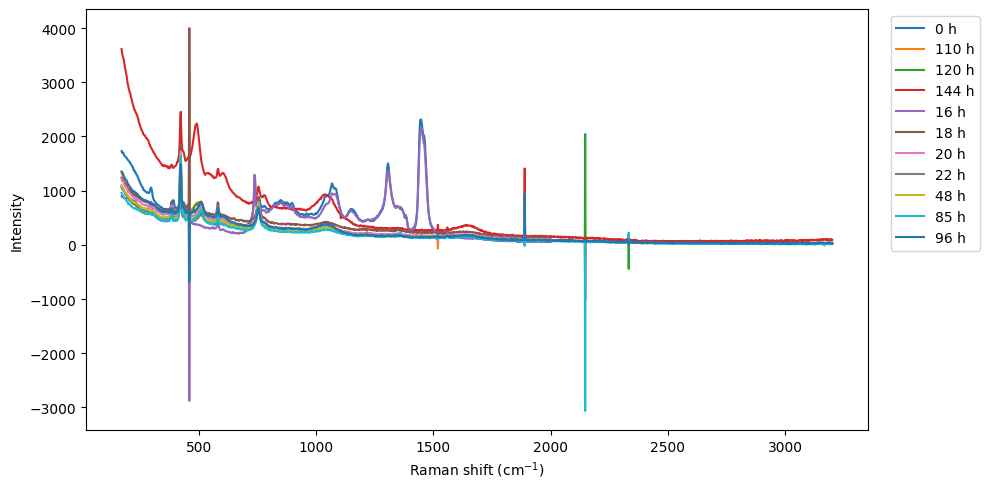

In [4]:
# Plot all the raw spectra:

plt.figure(figsize=(10, 5))
for s in spectra:
    plt.plot(s["x"], s["y"], label=f"{s['time']:g} h")
plt.xlabel(r"Raman shift (cm$^{-1}$)")
plt.ylabel("Intensity")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

The spectra acquired at 0 and 16 h were not used in the following analysis, as the Raman features associated with the crystalline zeolite phases were not yet sufficiently informative. We therefore continue the analysis from 18 h onward:

In [5]:
spectra = [s for s in spectra_all if s["time"] >= 18]
times = np.array([s["time"] for s in spectra])

## 2. Crop and interpolate the spectra onto a common Raman-shift axis

The first preprocessing step is to remove spectral regions that we are not going to use. For this dataset I keep the **250–1250 cm⁻¹** region.

The spectra were not all recorded on exactly the same Raman-shift axis, so after cropping, each spectrum is interpolated onto a common axis. This is necessary before combining the spectra into a single data matrix for the following preprocessing steps and NNLS analysis.

Importantly, both cropping and interpolation are done *before* spike removal and baseline subtraction, so these algorithms only operate on the relevant and harmonized part of the signal.

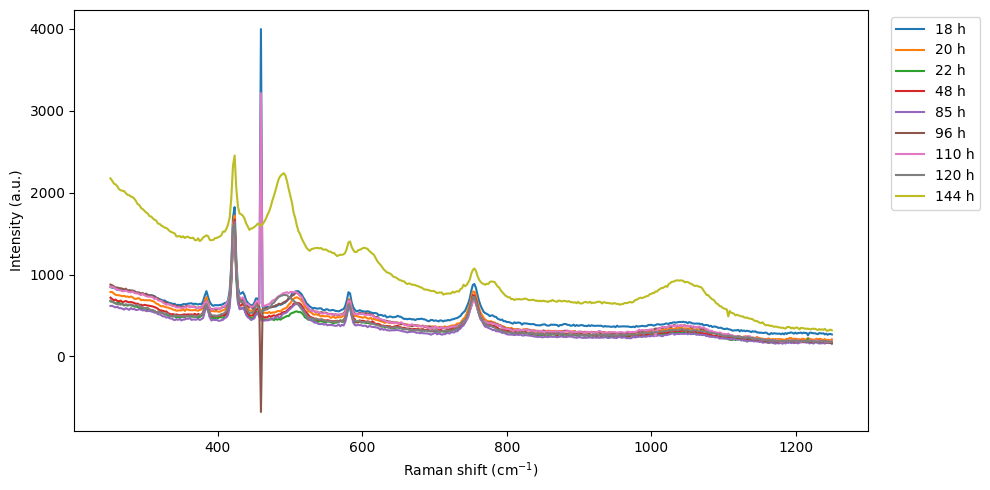

Common Raman range: 251.84 - 1249.52 cm-1
Common number of points: 468
Y_raw shape: (9, 468)


In [6]:
# ----------------------------------------------------------
# Crop + interpolate all spectra to a common Raman-shift axis
# ----------------------------------------------------------

low_end = 250
high_end = 1250

# Find the spectral range that is actually available in ALL spectra
x_min = max(low_end, max(np.min(s["x"]) for s in spectra))
x_max = min(high_end, min(np.max(s["x"]) for s in spectra))

# Use the first spectrum as the reference axis
x0 = spectra[0]["x"]
mask_ref = (x0 >= x_min) & (x0 <= x_max)
x_crop = x0[mask_ref]

# Make sure the common axis goes from low to high Raman shift
x_crop = np.sort(x_crop)

Y_raw = []

for s in spectra:

    x = s["x"]
    y = s["y"]

    # Crop each spectrum individually
    mask = (x >= x_min) & (x <= x_max)

    x_i = x[mask]
    y_i = y[mask]

    # np.interp requires increasing x
    order = np.argsort(x_i)
    x_i = x_i[order]
    y_i = y_i[order]

    # Interpolate onto the common axis
    y_interp = np.interp(x_crop, x_i, y_i)

    Y_raw.append(y_interp)

Y_raw = np.array(Y_raw)


# ----------------------------------------------------------
# Plot
# ----------------------------------------------------------
plt.figure(figsize=(10, 5))
for t, y in zip(times, Y_raw):
    plt.plot(x_crop, y, label=f"{t:g} h")
plt.xlabel(r"Raman shift (cm$^{-1}$)")
plt.ylabel("Intensity (a.u.)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("Common Raman range:", x_crop.min(), "-", x_crop.max(), "cm-1")
print("Common number of points:", len(x_crop))
print("Y_raw shape:", Y_raw.shape)

## 3. Remove spikes

Cosmic rays and detector artifacts can generate very narrow positive, and sometimes negative, features, named spikes. A single spike can strongly affect normalization or multivariate model performance.

Here I use the prominence-width spike removal approach developed in **“An intuitive approach for spike removal in Raman spectra based on peaks’ prominence and width”**  
(https://doi.org/10.1016/j.aca.2024.342312). The idea is intuitive: Spikes are unusually narrower than real Raman bands. This algorithm finds all peaks in the spectra and set a threshold in their prominence and width to detect spikes. The implementation below also applies the same logic to `-y`, allowing negative spikes to be detected.

In [7]:
from scipy.signal import find_peaks, peak_widths
from scipy import interpolate
import warnings


def spike_removal(
    y,
    width_threshold,
    prominence_threshold,
    interpolation_window=10,
    width_param_rel=0.8,
    interp_kind="linear",
    remove_positive=True,
    remove_negative=True,
):
    """Remove narrow spikes from a Raman spectrum using peak prominence and width.

    Spike detection is based on the prominence/FWHM approach described in:
    N. Coca-Lopez,
    "An intuitive approach for spike removal in Raman spectra based on
    peaks' prominence and width",
    Analytica Chimica Acta 1295 (2024) 342312.
    https://doi.org/10.1016/j.aca.2024.342312

    Peaks with sufficient prominence above 'prominence_threshold' and a width below 
    'width_threshold' are classified as spikes and replaced by interpolation from 
    neighboring non-corrupted points.

    This implementation extends the original approach by optionally detecting
    negative spikes through the same procedure applied to -y. It also uses
    conservative checks to avoid extrapolation or interpolation when clean
    data are not available on both sides of a detected spike."""
    
    y = np.asarray(y, dtype=float)

    def detect_spikes(signal):
        spike_mask = np.zeros(len(signal), dtype=bool)
        peaks, _ = find_peaks(signal, prominence=prominence_threshold)

        if len(peaks) == 0:
            return spike_mask

        widths = peak_widths(signal, peaks, rel_height=0.5)[0]
        width_results = peak_widths(signal, peaks, rel_height=width_param_rel)

        for width, left, right in zip(widths, width_results[2], width_results[3]):
            if width < width_threshold:
                start = max(int(np.floor(left)) - 1, 0)
                end = min(int(np.ceil(right)) + 2, len(signal))
                spike_mask[start:end] = True

        return spike_mask

    spikes = np.zeros(len(y), dtype=bool)

    if remove_positive:
        spikes |= detect_spikes(y)
    if remove_negative:
        spikes |= detect_spikes(-y)

    if not np.any(spikes):
        return y.copy()

    y_out = y.copy()
    padded = np.r_[False, spikes, False]
    changes = np.diff(padded.astype(int))
    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0] - 1

    required = {"linear": 2, "quadratic": 3, "cubic": 4}
    if interp_kind not in required:
        raise ValueError("interp_kind must be 'linear', 'quadratic', or 'cubic'.")

    skipped = []

    for start, end in zip(starts, ends):
        window = np.arange(
            max(start - interpolation_window, 0),
            min(end + interpolation_window + 1, len(y)),
        )

        good = window[~spikes[window]]
        bad = np.arange(start, end + 1)

        if len(good) < required[interp_kind]:
            skipped.append((start, end, "not enough clean points"))
            continue

        if not np.any(good < start) or not np.any(good > end):
            skipped.append((start, end, "no clean data on both sides"))
            continue

        if bad[0] < good.min() or bad[-1] > good.max():
            skipped.append((start, end, "would require extrapolation"))
            continue

        try:
            f = interpolate.interp1d(
                good,
                y[good],
                kind=interp_kind,
                bounds_error=True,
            )
            y_out[bad] = f(bad)
        except ValueError:
            skipped.append((start, end, "interpolation failed"))

    if skipped:
        warnings.warn(
            f"{len(skipped)} spike region(s) were not corrected because "
            f"interpolation was considered unsafe: {skipped[:10]}"
        )

    return y_out

The following cell applies the spike removal algorithm to all the spectra and plots the spectra before and after spectra correction. The two parameters worth checking visually are `WIDTH_THRESHOLD` and `PROMINENCE_THRESHOLD`. They should be tuned considering the spectral resolution and the width of real Raman bands.

Spectra containing corrected spikes: 3
Times: [ 18.  96. 110.]


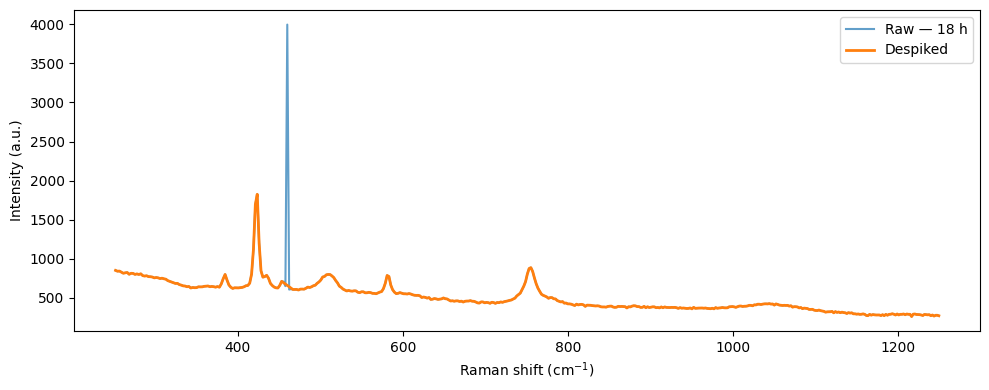

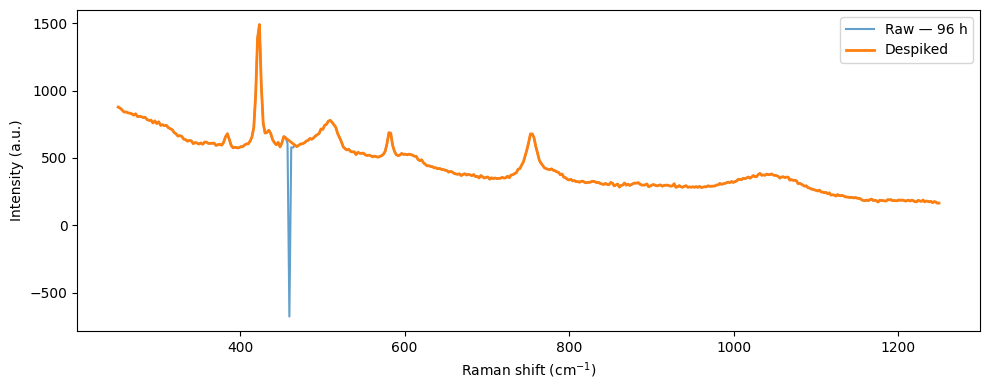

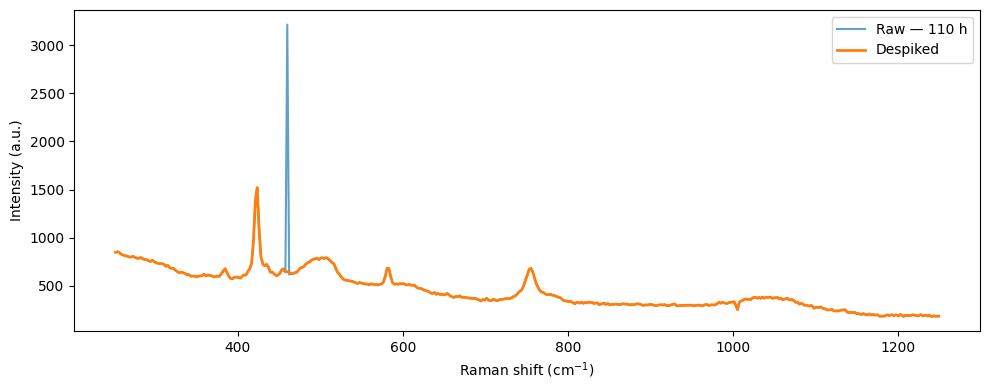

In [8]:
WIDTH_THRESHOLD = 2
PROMINENCE_THRESHOLD = 100
WINDOW = 5

Y_despiked = np.array([
    spike_removal(
        y,
        width_threshold=WIDTH_THRESHOLD,
        prominence_threshold=PROMINENCE_THRESHOLD,
        interpolation_window=WINDOW,
    )
    for y in Y_raw
])

# Find spectra that were modified by spike removal
affected = np.where(
    np.any(~np.isclose(Y_raw, Y_despiked), axis=1)
)[0]

print(f"Spectra containing corrected spikes: {len(affected)}")
print("Times:", times[affected])

# Plot every affected spectrum
for i in affected:

    plt.figure(figsize=(10, 4))

    plt.plot(
        x_crop,
        Y_raw[i],
        label=f"Raw — {times[i]:g} h",
        alpha=0.7
    )

    plt.plot(
        x_crop,
        Y_despiked[i],
        label="Despiked",
        lw=2
    )

    plt.xlabel(r"Raman shift (cm$^{-1}$)")
    plt.ylabel("Intensity (a.u.)")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 4. Baseline subtraction

The next major artifact is the slowly varying spectral background. Here I use **asymmetric least squares (AsLS)** baseline estimation, implemented in the library pybaselines by D. Erb (https://github.com/derb12/pybaselines).

The parameters are kept close to those used in the original analysis:

- `lam = 3e3`: baseline smoothness.
- `p = 0.001`: asymmetry parameter.
- `max_iter = 300`: maximum iterations.

The following cell shows the correction of the spectra:

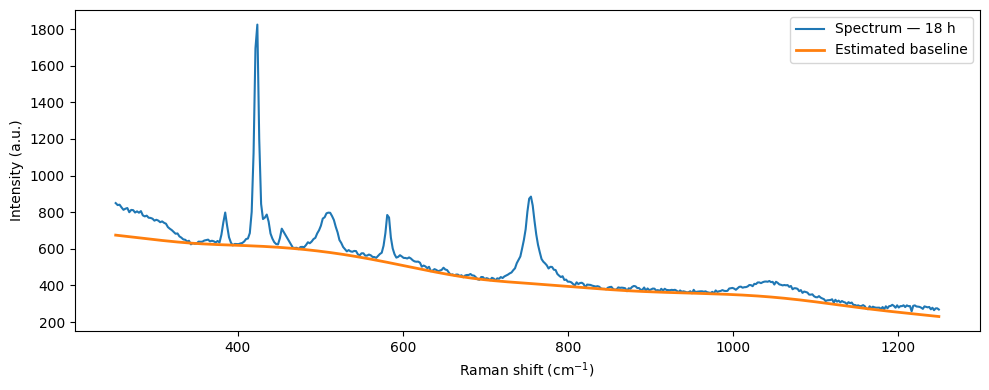

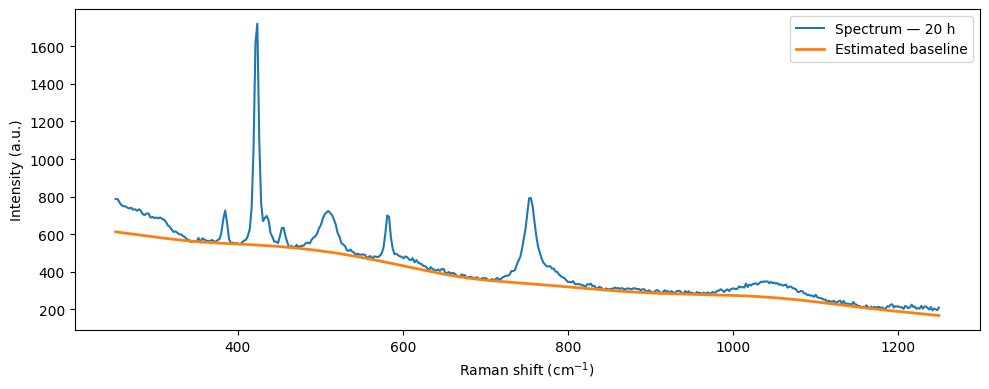

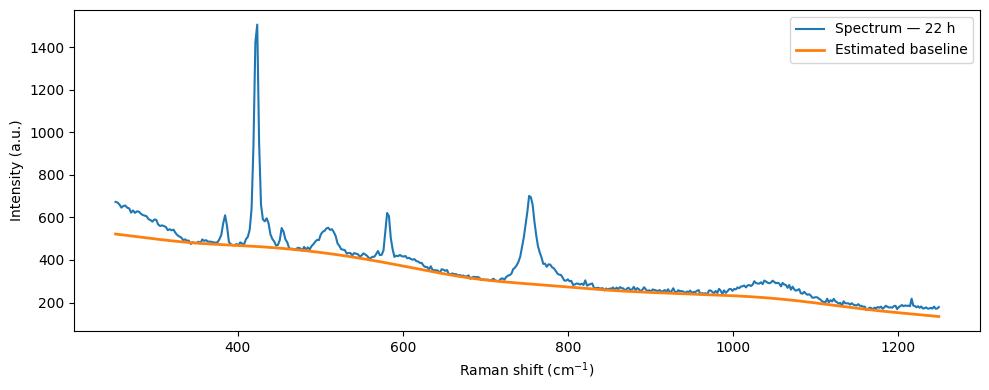

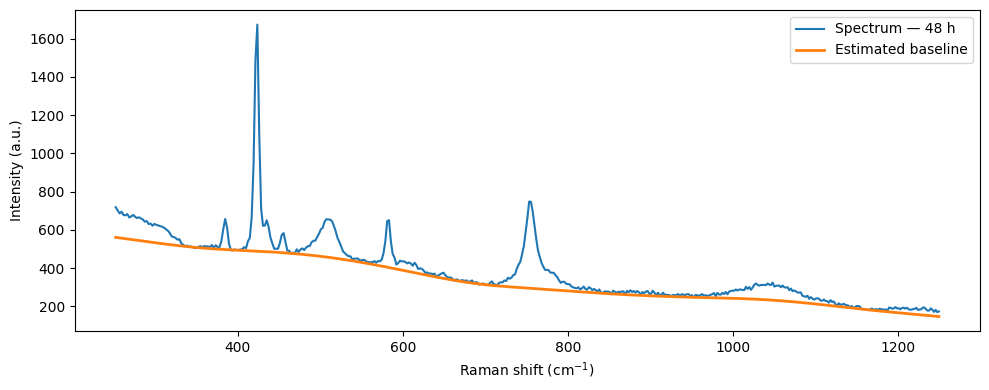

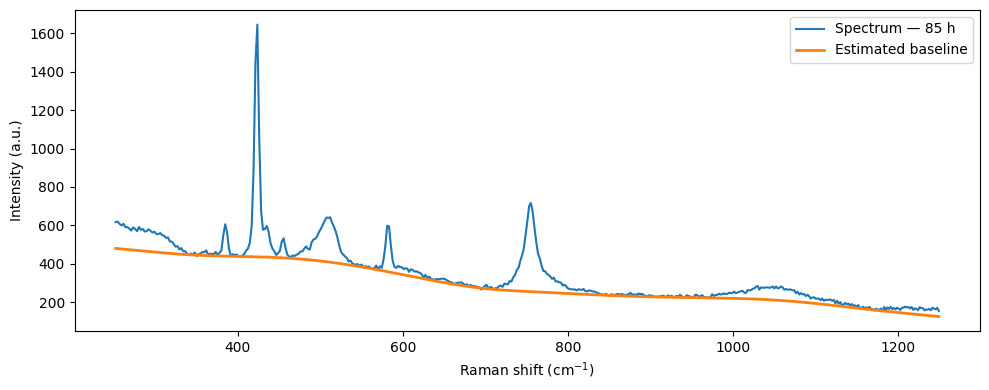

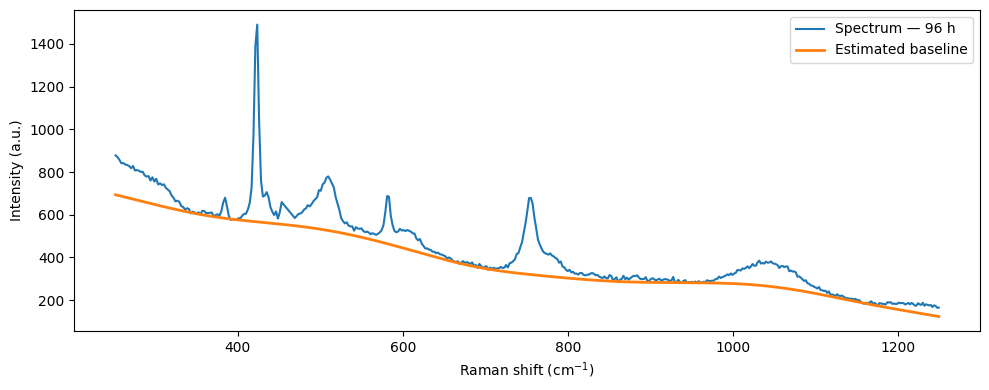

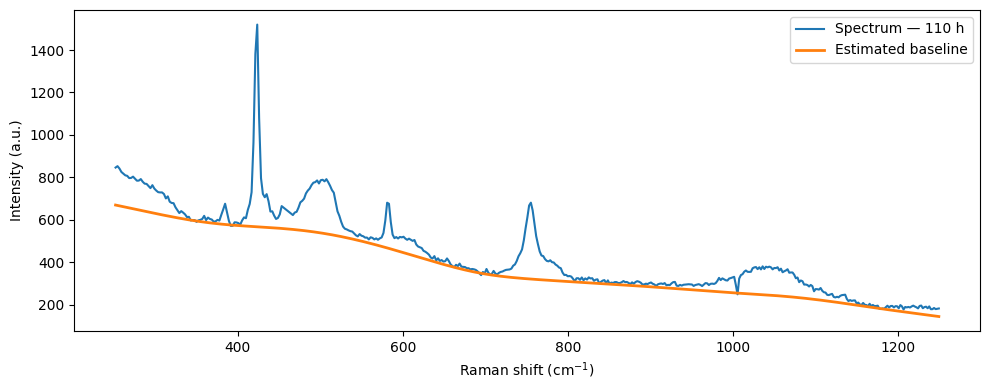

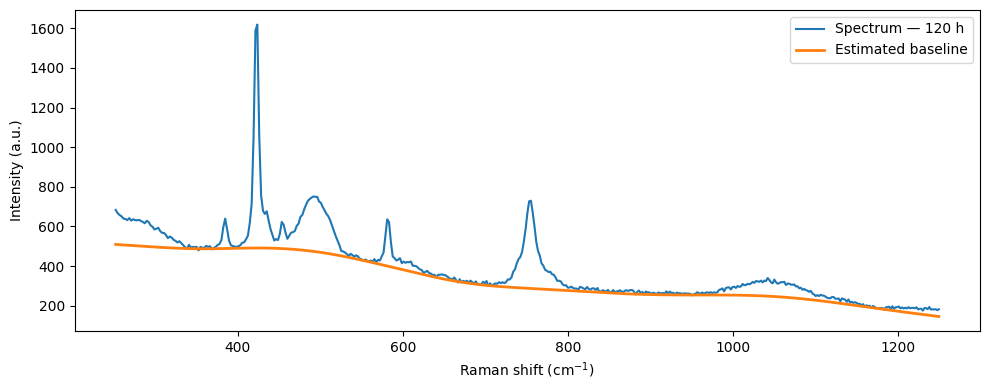

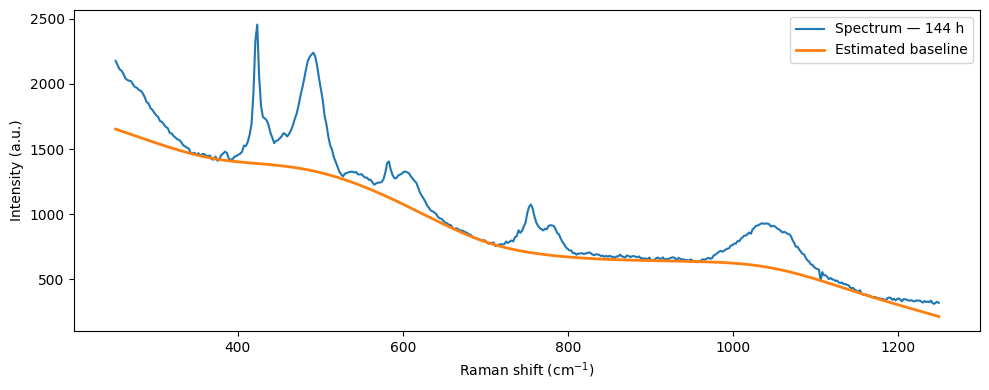

In [9]:
from pybaselines import Baseline

baseline_fitter = Baseline(x_data=x_crop)

baselines = []
Y_corrected = []

for y in Y_despiked:
    baseline, _ = baseline_fitter.asls(
        y,
        lam=3e3,
        p=0.001,
        max_iter=300
    )

    baselines.append(baseline)
    Y_corrected.append(y - baseline)

baselines = np.array(baselines)
Y_corrected = np.array(Y_corrected)


# Plot all spectra with their estimated baselines
for i in range(len(Y_despiked)):
    plt.figure(figsize=(10, 4))
    plt.plot(x_crop, Y_despiked[i], label=f"Spectrum — {times[i]:g} h")
    plt.plot(x_crop, baselines[i], label="Estimated baseline", lw=2)
    plt.xlabel(r"Raman shift (cm$^{-1}$)")
    plt.ylabel("Intensity (a.u.)")
    plt.legend()
    plt.tight_layout()
    plt.show()

Let's take a look to all spectra together:

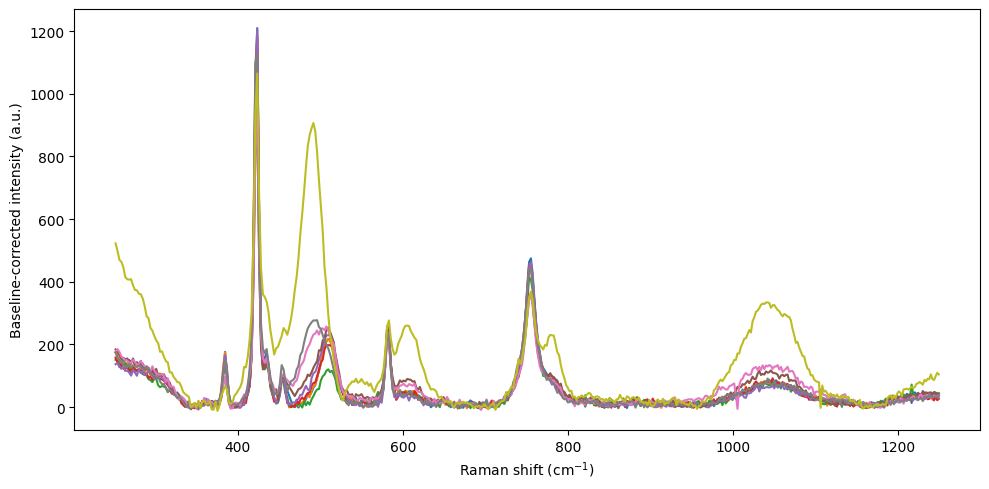

In [10]:
plt.figure(figsize=(10, 5))

for t, y in zip(times, Y_corrected):
    plt.plot(x_crop, y, label=f"{t:g} h")

plt.xlabel(r"Raman shift (cm$^{-1}$)")
plt.ylabel("Baseline-corrected intensity (a.u.)")
plt.tight_layout()
plt.show()

## 5. Focus on the FAU/GIS diagnostic region

For the NNLS analysis we do not need the complete Raman spectrum. The most useful evolution occurs in the narrow region containing characteristic FAU/GIS framework bands.

We therefore:

1. crop to **460–540 cm⁻¹**,
2. normalize each spectrum by its summed intensity,

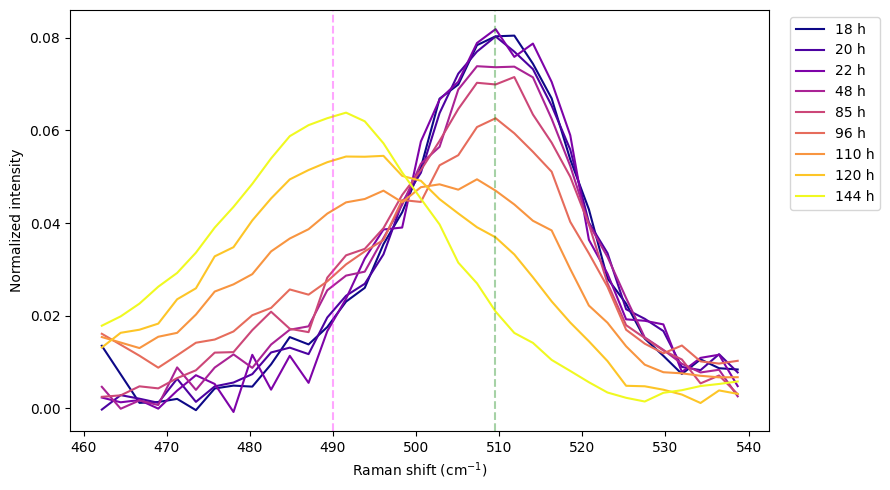

In [11]:
mask_nnls = (x_crop >= 460) & (x_crop <= 540)

x_nnls = x_crop[mask_nnls]
Y_nnls = Y_corrected[:, mask_nnls].copy()
Y_nnls /= Y_nnls.sum(axis=1, keepdims=True)

cmap = plt.cm.plasma

plt.figure(figsize=(9, 5))
for i, (t, y) in enumerate(zip(times, Y_nnls)):
    plt.plot(x_nnls, y, color=cmap(i / (len(times) - 1)), label=f"{t:g} h")

plt.axvline(490, color="magenta", alpha=0.35, ls="--")
plt.axvline(509.5, color="green", alpha=0.35, ls="--")
plt.xlabel(r"Raman shift (cm$^{-1}$)")
plt.ylabel("Normalized intensity")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 6. Non-Negative Least Squares

A Raman spectrum (y) containing two phases can be approximated as a linear combination of the two reference spectra ($S_{\mathrm{FAU}}$ and $S_{\mathrm{GIS}}$):

$y \approx C_{\mathrm{FAU}} S_{\mathrm{FAU}} + C_{\mathrm{GIS}} S_{\mathrm{GIS}}$

where $C_{\mathrm{FAU}}$ and $C_{\mathrm{GIS}}$ are the corresponding coefficients. NNLS constrains the coefficients to be non-negative:

$\min_{c \ge 0}\|SC-y\|_2$

This makes NNLS attractive for simple spectral unmixing: the model is fast, transparent and easy to interpret.

### Reference spectra

Here, the spectra acquired at **18 h** and **144 h** are used as the FAU and GIS reference spectra, respectively.

In [12]:
from scipy.optimize import nnls

FAU_TIME = 18
GIS_TIME = 144

i_fau = np.argmin(np.abs(times - FAU_TIME))
i_gis = np.argmin(np.abs(times - GIS_TIME))

R = np.column_stack([Y_nnls[i_fau], Y_nnls[i_gis]])

coef = np.array([nnls(R, y)[0] for y in Y_nnls])
# From coefficients to weighted fractions:
fractions = 100 * coef / coef.sum(axis=1, keepdims=True)

fau_fraction = fractions[:, 0]
gis_fraction = fractions[:, 1]

The following plot shows the evolution of both phases:

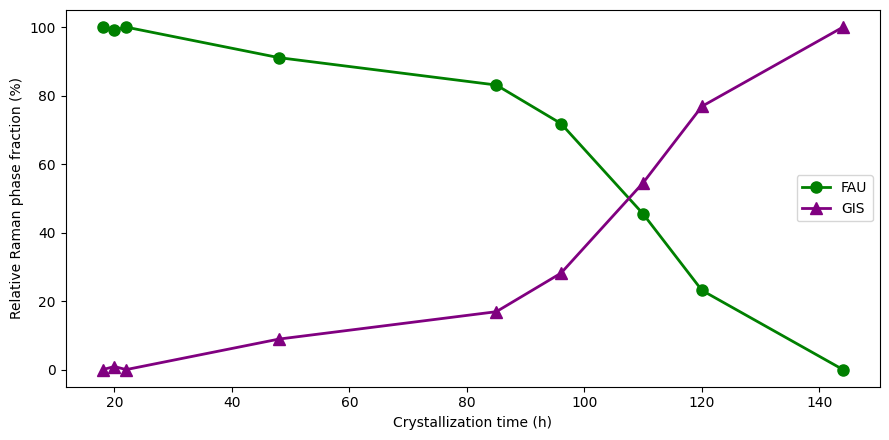

In [30]:
plt.figure(figsize=(9, 4.5))
plt.plot(times, fau_fraction, "o-", color="green", label="FAU", lw=2, ms=8)
plt.plot(times, gis_fraction, "^-", color="purple", label="GIS", lw=2, ms=8)

plt.xlabel("Crystallization time (h)")
plt.ylabel("Relative Raman phase fraction (%)")
plt.legend()

plt.tight_layout()
plt.show()

## What did we do?

The complete workflow was:

**raw Raman spectra → crop → spike removal → baseline subtraction → diagnostic-region crop → normalization → NNLS**

The interesting part is that the final model is extremely simple. Once the spectra are properly preprocessed, NNLS needs only two reference signatures to recover the relative evolution of the two crystalline phases.

In the full paper, the Raman-derived FAU/GIS evolution is compared with ex situ XRD/Rietveld analysis and forms part of a broader process-monitoring study. Here we deliberately keep only the data-processing side so every step remains transparent and reproducible.

## Data and references

**Main paper**  
N. Coca-Lopez *et al.*, *Process monitoring of zeolite crystallization: Bridging in situ Raman spectroscopy, ex situ XRD, and predictive machine learning models*, Chemical Engineering Journal 543 (2026) 177865.  
https://doi.org/10.1016/j.cej.2026.177865

**Open dataset**  
*Process Monitoring of Zeolite Crystallization: Bridging In situ Raman Spectroscopy, Ex situ XRD, and Predictive Machine Learning Models*, Zenodo.  
https://doi.org/10.5281/zenodo.18972297

**Spike removal**  
N. Coca-Lopez, *An intuitive approach for spike removal in Raman spectra based on peaks’ prominence and width*, Analytica Chimica Acta 1295 (2024) 342312.  
https://doi.org/10.1016/j.aca.2024.342312

**Further information on Raman spectra processing**  
N. Coca-Lopez *et al.*, *Artificial Intelligence-Powered Raman Spectroscopy through Open Science and FAIR Principles*, ACS Nano 11 November 2025; 19 (44): 38189–38218.  
https://doi.org/10.1021/acsnano.5c09165
